In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Loading the model
the ones that worked : 
transformers: 4.45.2
torch: 2.10.0+cu128
tokenizers: 0.20.3

In [ ]:
import transformers, torch, tokenizers
print("transformers:", transformers.__version__)
print("torch:", torch.__version__)
print("tokenizers:", tokenizers.__version__)

In [ ]:
!pip install transformers tokenizers --upgrade -q

In [ ]:
!pip index versions transformers 2>/dev/null | head -5
!pip install "transformers>=4.40.0,<4.46.0" "tokenizers>=0.20.0" -q

In [ ]:
!pip install transformers==4.47.0 tokenizers==0.20.3 -q --force-reinstall

In [ ]:
from transformers import AutoProcessor, LlavaForConditionalGeneration
import torch

model = LlavaForConditionalGeneration.from_pretrained(
    "llava-hf/llava-1.5-7b-hf",
    torch_dtype=torch.float16,
    device_map="auto"
)

processor = AutoProcessor.from_pretrained("llava-hf/llava-1.5-7b-hf") # # Process both text AND image together

print("✅ Model loaded successfully!")

In [ ]:
# Save model and processor to Kaggle output folder
model.save_pretrained("/kaggle/working/llava-local")
processor.save_pretrained("/kaggle/working/llava-local")
print("✅ Saved!")

In [ ]:
import os

for item in os.listdir("/kaggle/working/llava-local"):
    size = os.path.getsize(f"/kaggle/working/llava-local/{item}")
    print(f"{item} — {size/1e9:.2f} GB" if size > 1e8 else f"{item} — {size/1e6:.1f} MB")

# **TRying out the model (Inference)** 

In [ ]:
from PIL import Image
import requests
from io import BytesIO

# Try this URL instead
url = "https://openi.nlm.nih.gov/imgs/512/145/145/CXR145_IM-0290-1001.png"
response = requests.get(url)
image = Image.open(BytesIO(response.content)).convert("RGB")

print("Image loaded! Size:", image.size)

In [ ]:
from PIL import Image
import requests
from io import BytesIO

# Fix: download fully then open
url = "https://openi.nlm.nih.gov/imgs/512/145/145/CXR145_IM-0290-1001.png"
response = requests.get(url)
image = Image.open(BytesIO(response.content)).convert("RGB")

# Format the prompt
prompt = "USER: <image>\nYou are a radiologist. Describe any findings in this chest X-ray and generate a radiology report.\nASSISTANT:"

# Process inputs
inputs = processor(text=prompt, images=image, return_tensors="pt").to("cuda", torch.float16)

# Generate output
with torch.no_grad():
    output = model.generate(
        **inputs,
        max_new_tokens=300,
        do_sample=False # greedy encoding : Always picks the token with the highest probability at each step.
    )

# Decode and print
response = processor.decode(output[0], skip_special_tokens=True) # decode here means move from numerical output to human readab;e output
print(response.split("ASSISTANT:")[-1].strip())

# Loading the data 

In [2]:
import pandas as pd 
training_data = pd.read_json('/kaggle/input/datasets/habibaadawi/training-data-jason/training_data.json')
training_data

,image_path,uid,conversations
0,data/images/images_normalized/1_IM-0001-4001.d...,1,"[{'role': 'user', 'content': '<image> You are ..."
1,data/images/images_normalized/2_IM-0652-1001.d...,2,"[{'role': 'user', 'content': '<image> You are ..."
2,data/images/images_normalized/4_IM-2050-1001.d...,4,"[{'role': 'user', 'content': '<image> You are ..."
3,data/images/images_normalized/5_IM-2117-100300...,5,"[{'role': 'user', 'content': '<image> You are ..."
4,data/images/images_normalized/6_IM-2192-1001.d...,6,"[{'role': 'user', 'content': '<image> You are ..."
...,...,...,...
3296,data/images/images_normalized/3993_IM-2044-100...,3993,"[{'role': 'user', 'content': '<image> You are ..."
3297,data/images/images_normalized/3994_IM-2045-200...,3994,"[{'role': 'user', 'content': '<image> You are ..."
3298,data/images/images_normalized/3995_IM-2046-100...,3995,"[{'role': 'user', 'content': '<image> You are ..."
3299,data/images/images_normalized/3996_IM-2047-100...,3996,"[{'role': 'user', 'content': '<image> You are ..."


In [3]:
import json
import os

# Load the JSON
with open('/kaggle/input/datasets/habibaadawi/training-data-jason/training_data.json') as f:
    data = json.load(f)

# Fix image paths to point to Kaggle dataset
kaggle_image_dir = "/kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalized"

for item in data:
    filename = os.path.basename(item['image_path'])
    item['image_path'] = f"{kaggle_image_dir}/{filename}"

# Verify first path exists
print("First image path:", data[0]['image_path'])
print("File exists:", os.path.exists(data[0]['image_path']))
print("Total samples:", len(data))

First image path: /kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalized/1_IM-0001-4001.dcm.png
File exists: True
Total samples: 3301


In [ ]:
with open("/kaggle/input/datasets/habibaadawi/chest-xrays-indiana-university/images/images_normalized") as f:
    data = json.load(f)

In [ ]:
os.listdir('/kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalized')

# SETTING UP QLORA

In [ ]:
!pip install datasets -q --upgrade

In [4]:
import json
import torch
import os
from PIL import Image
from torch.utils.data import Dataset
from transformers import AutoProcessor, LlavaForConditionalGeneration, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import TrainingArguments, Trainer


In [5]:
# ── 1. Fix paths ──────────────────────────────────────────────
with open('/kaggle/input/datasets/habibaadawi/training-data-jason/training_data.json') as f:
    data = json.load(f)

kaggle_image_dir = "/kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalized"
for item in data:
    filename = os.path.basename(item['image_path'])
    item['image_path'] = f"{kaggle_image_dir}/{filename}"
print(data)

[{'image_path': '/kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalized/1_IM-0001-4001.dcm.png', 'uid': 1, 'conversations': [{'role': 'user', 'content': '<image>\nYou are an expert radiologist. Analyze this chest X-ray and generate a detailed radiology report including findings and impression.'}, {'role': 'assistant', 'content': 'FINDINGS: The cardiac silhouette and mediastinum size are within normal limits. There is no pulmonary edema. There is no focal consolidation. There are no XXXX of a pleural effusion. There is no evidence of pneumothorax.\n\nIMPRESSION: Normal chest x-XXXX.'}]}, {'image_path': '/kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalized/2_IM-0652-1001.dcm.png', 'uid': 2, 'conversations': [{'role': 'user', 'content': '<image>\nYou are an expert radiologist. Analyze this chest X-ray and generate a detailed radiology report including findings and impression.'}, {'role': 'assistant', 'content': 'FINDINGS: Bor

In [ ]:
# Cell 1 - Installing model from scratch 
!pip install bitsandbytes>=0.46.1 peft -q

# Cell 2 - imports
import torch
import os
from transformers import AutoProcessor, LlavaForConditionalGeneration, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

# Cell 3 - clear GPU memory
import gc
gc.collect() # python garabage collection 
torch.cuda.empty_cache()
print("GPU memory cleared") # Why? Prevents OOM (Out of Memory) errors from previous runs.

# Cell 4 - QLoRA config
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16 # Stored as 4-bit, computed as 16-bit
)

# Cell 5 - load model
model = LlavaForConditionalGeneration.from_pretrained(
    "llava-hf/llava-1.5-7b-hf",
    quantization_config=bnb_config,
    device_map="auto"
)
processor = AutoProcessor.from_pretrained("llava-hf/llava-1.5-7b-hf")
processor.tokenizer.padding_side = "right" # to make sure all batchs are of the same size 
print("✅ Model loaded!")

# Cell 6 - prepare QLoRA
model = prepare_model_for_kbit_training(model)
lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=["q_proj", "v_proj", "k_proj", "o_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM"
)
model = get_peft_model(model, lora_config) #wraps the base model with the Olora adapters 
model.print_trainable_parameters()

GPU memory cleared


config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/41.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/552 [00:00<?, ?B/s]

✅ Model loaded!
trainable params: 19,136,512 || all params: 7,082,563,584 || trainable%: 0.2702


In [7]:
# ── 2. QLoRA Config ───────────────────────────────────────────
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16
)

In [ ]:
# Check cache first
cache_dir = os.path.expanduser("./.cache")
print(os.listdir(cache_dir))

In [ ]:
import os    # run this code if the model exists in your CACHE

# Check cache first
cache_dir = os.path.expanduser("~/.cache/huggingface/hub")
print(os.listdir(cache_dir))

# Load model
model = LlavaForConditionalGeneration.from_pretrained(
    "llava-hf/llava-1.5-7b-hf",
    quantization_config=bnb_config,
    device_map="auto",
    local_files_only=True
)
processor = AutoProcessor.from_pretrained(
    "llava-hf/llava-1.5-7b-hf",
    local_files_only=True
)
print("✅ Model loaded!")

In [ ]:
import os #.cache/huggingface/hub
# Check cache
cache_dir = os.path.expanduser("/kaggle/lib/kaggl/egcp.py")
print(os.listdir(cache_dir))

In [ ]:
!pip install bitsandbytes>=0.46.1 peft -q

In [8]:
model = prepare_model_for_kbit_training(model)

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=["q_proj", "v_proj", "k_proj", "o_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM"
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

/usr/local/lib/python3.12/dist-packages/peft/mapping_func.py:72: UserWarning: You are trying to modify a model with PEFT for a second time. If you want to reload the model with a different config, make sure to call `.unload()` before.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/peft/tuners/tuners_utils.py:285: UserWarning: Already found a `peft_config` attribute in the model. This will lead to having multiple adapters in the model. Make sure to know what you are doing!
  warnings.warn(


trainable params: 19,136,512 || all params: 7,082,563,584 || trainable%: 0.2702


# Training 

In [9]:
import json
import os
from PIL import Image
from torch.utils.data import Dataset
from transformers import TrainingArguments, Trainer

# ── Dataset ───────────────────────────────────────────────────
class XrayDataset(Dataset):
    def __init__(self, data, processor):
        self.data = data
        self.processor = processor

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]
        try:
            image = Image.open(item['image_path']).convert("RGB")
        except Exception:
            # Return next item if image is corrupted
            return self.__getitem__((idx + 1) % len(self.data))
        
        user_msg = item['conversations'][0]['content']
        assistant_msg = item['conversations'][1]['content']
        prompt = f"USER: {user_msg}\nASSISTANT: {assistant_msg}"
    
        inputs = self.processor(
            text=prompt,
            images=image,
            return_tensors="pt",
            padding="max_length",
            truncation=True,
            max_length=1024
        )
        inputs = {k: v.squeeze(0) for k, v in inputs.items()}
        inputs["labels"] = inputs["input_ids"].clone()
        return inputs

# ── Training Arguments ────────────────────────────────────────
training_args = TrainingArguments(
    output_dir="./checkpoints",
    num_train_epochs=1,
    per_device_train_batch_size=1,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,
    fp16=True,
    save_steps=100,
    save_total_limit=2,
    logging_steps=10,
    remove_unused_columns=False,
    report_to="none",
    dataloader_num_workers=0
)

# ── Load Data ─────────────────────────────────────────────────
with open('/kaggle/input/datasets/habibaadawi/training-data-jason/training_data.json') as f:
    data = json.load(f)

kaggle_image_dir = "/kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalized"
for item in data:
    filename = os.path.basename(item['image_path'])
    item['image_path'] = f"{kaggle_image_dir}/{filename}"

# ── Train ─────────────────────────────────────────────────────
dataset = XrayDataset(data, processor)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=dataset,
)

print("🚀 Starting training...")
# trainer.train()
trainer.train(resume_from_checkpoint="/kaggle/input/datasets/habibaadawi/checkpoints/checkpoint-700")

# ── Save ──────────────────────────────────────────────────────
model.save_pretrained("/kaggle/working/llava-finetuned")
processor.save_pretrained("/kaggle/working/llava-finetuned")
print("✅ Fine-tuning complete!")

🚀 Starting training...


/usr/local/lib/python3.12/dist-packages/torch/_dynamo/eval_frame.py:1181: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning: The AccumulateGrad node's stream does not match the stream of the node that produced the incoming gradient. This may incur unnecessary synchronization and break CUDA graph capture if the AccumulateGrad node's stream is the default stream. This mismatch is caused by an AccumulateGrad node created prior to the current iteration being kept alive. This can happen if the autograd graph is still being kept alive by tensors such a

Step,Training Loss
710,10.719534
720,6.756666
730,4.347826
740,4.038464
750,3.913527
760,3.880113
770,3.827474
780,3.776930
790,3.737892
800,3.725661


/usr/local/lib/python3.12/dist-packages/torch/_dynamo/eval_frame.py:1181: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


✅ Fine-tuning complete!


In [ ]:
import os

# Define the directory where you want to save the QLoRA weights
output_dir = "./qlora_cv_model"

# Save the adapter weights and the configuration
trainer.model.save_pretrained(output_dir)

# Save the tokenizer so it matches the model during inference
tokenizer.save_pretrained(output_dir)

print(f"✅ Model and tokenizer saved successfully to {output_dir}")

In [10]:
import os 
os.listdir('/kaggle/working/llava-finetuned')

['processor_config.json',
 'checkpoint-500',
 'tokenizer.json',
 'chat_template.jinja',
 'adapter_config.json',
 'tokenizer_config.json',
 'checkpoint-400',
 'adapter_model.safetensors',
 'README.md']

In [ ]:
#If you want to download a checkpoint or checkpoints 
import shutil 
import os

# Zip the checkpoint so it's one file to download
shutil.make_archive(
    "/kaggle/working/checkpoint-700-backup",  # output file name
    'zip',                                      # format
    "./checkpoints",                            # source folder
    "checkpoint-700"                            # folder to zip
)

print("✅ Zipped! Size:")
size = os.path.getsize("/kaggle/working/checkpoint-700-backup.zip")
print(f"{size/1e6:.1f} MB")

In [12]:
from IPython.display import FileLink
import os

# Define your directory and zip file name
dir_to_zip = "/kaggle/working/llava-finetuned"
zip_filename = "llava-finetuned.zip"

# Compress the folder
!zip -r {zip_filename} {dir_to_zip}

# Generate a clickable download link
FileLink(zip_filename)

  adding: kaggle/working/llava-finetuned/ (stored 0%)
  adding: kaggle/working/llava-finetuned/processor_config.json (deflated 52%)
  adding: kaggle/working/llava-finetuned/checkpoint-500/ (stored 0%)
  adding: kaggle/working/llava-finetuned/checkpoint-500/adapter_config.json (deflated 58%)
  adding: kaggle/working/llava-finetuned/checkpoint-500/adapter_model.safetensors (deflated 54%)
  adding: kaggle/working/llava-finetuned/tokenizer.json (deflated 85%)
  adding: kaggle/working/llava-finetuned/chat_template.jinja (deflated 62%)
  adding: kaggle/working/llava-finetuned/adapter_config.json (deflated 59%)
  adding: kaggle/working/llava-finetuned/tokenizer_config.json (deflated 51%)
  adding: kaggle/working/llava-finetuned/checkpoint-400/ (stored 0%)
  adding: kaggle/working/llava-finetuned/checkpoint-400/adapter_config.json (deflated 58%)
  adding: kaggle/working/llava-finetuned/checkpoint-400/adapter_model.safetensors (deflated 54%)
  adding: kaggle/working/llava-finetuned/adapter_mode

/kaggle/working/llava-finetuned.zip

In [17]:
model 

PeftModelForCausalLM(
  (base_model): LoraModel(
    (model): PeftModelForCausalLM(
      (base_model): LoraModel(
        (model): LlavaForConditionalGeneration(
          (model): LlavaModel(
            (vision_tower): CLIPVisionModel(
              (vision_model): CLIPVisionTransformer(
                (embeddings): CLIPVisionEmbeddings(
                  (patch_embedding): Conv2d(3, 1024, kernel_size=(14, 14), stride=(14, 14), bias=False)
                  (position_embedding): Embedding(577, 1024)
                )
                (pre_layrnorm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
                (encoder): CLIPEncoder(
                  (layers): ModuleList(
                    (0-23): 24 x CLIPEncoderLayer(
                      (self_attn): CLIPAttention(
                        (k_proj): lora.Linear4bit(
                          (base_layer): Linear4bit(in_features=1024, out_features=1024, bias=True)
                          (lora_dropout): ModuleDict(
 

# Attaching fine tuned adapter to the base model

In [3]:
import torch
from transformers import AutoProcessor
from peft import PeftModel

# 1. Define the adapter path
adapter_path = "/kaggle/working/llava-finetuned"

# 2. Attach the fine-tuned adapter directly to your existing base model
print("🔌 Attaching fine-tuned adapter to existing model...")
model = PeftModel.from_pretrained(model, adapter_path)

# 3. Load the processor
print("☕ Loading processor...")
processor = AutoProcessor.from_pretrained("llava-hf/llava-1.5-7b-hf")
processor.tokenizer.padding_side = "right"

print("✅ Model is ready for inference!")

🔌 Attaching fine-tuned adapter to existing model...


NameError: name 'model' is not defined

# Infering the new model

## Trying out injured leg image 

In [5]:
import torch
from PIL import Image

# 1. Load the X-ray image directly from your local Kaggle path
image_path = "/kaggle/input/datasets/habibaadawi/injured-leg/xray_injured_leg.jpg"
image = Image.open(image_path).convert("RGB")
print("✅ Image loaded successfully from local storage!")

# 2. Prepare the prompt for LLaVA
prompt = "USER: <image>\nAnalyze this X-ray and generate a findings report.\nASSISTANT:"

# 3. Process the inputs
device = "cuda" if torch.cuda.is_available() else "cpu"
inputs = processor(text=prompt, images=image, return_tensors="pt").to(device)

# 4. Generate the report
print("🤖 Generating report...")
with torch.inference_mode():
    outputs = model.generate(**inputs, max_new_tokens=250, do_sample=False)

# Decode the output
report = processor.decode(outputs[0], skip_special_tokens=True)

# Clean the output to only show the assistant's response
if "ASSISTANT:" in report:
    report = report.split("ASSISTANT:")[-1].strip()

print(f"\n📋 **Generated Report:**\n{report}\n")

✅ Image loaded successfully from local storage!
🤖 Generating report...

📋 **Generated Report:**
The image displays a black and white X-ray of a person's leg, showing a broken bone. The bone is located near the knee, and the leg appears to be in a cast. The X-ray provides a clear view of the fracture and the surrounding tissues, allowing for a proper diagnosis and treatment plan. The patient may require medical attention and physical therapy to recover from the injury and regain full mobility.



In [6]:
import torch
from PIL import Image

# 1. Load the X-ray image directly from your local Kaggle path
image_path = "/kaggle/input/datasets/habibaadawi/injured-leg/xray_injured_leg.jpg"
image = Image.open(image_path).convert("RGB")
print("✅ Image loaded successfully from local storage!")

# 2. Prepare the prompt for LLaVA
# Note: Using the base model directly might require slightly different prompt formatting 
# depending on your specific version of LLaVA.
prompt = "USER: <image>\nAnalyze this X-ray and generate a findings report.\nASSISTANT:"

# 3. Process the inputs
device = "cuda" if torch.cuda.is_available() else "cpu"

# Ensure inputs are moved to the same device as the base model
inputs = processor(text=prompt, images=image, return_tensors="pt").to(device)

# 4. Generate the report
print("🤖 Generating report using the base model...")
with torch.inference_mode():
    # We call model.generate directly on the base model
    outputs = model.generate(**inputs, max_new_tokens=250, do_sample=False)

# 5. Decode the output
report = processor.decode(outputs[0], skip_special_tokens=True)

# 6. Clean the output to only show the assistant's response
if "ASSISTANT:" in report:
    report = report.split("ASSISTANT:")[-1].strip()

print(f"\n📋 **Generated Report (Base Model):**\n{report}\n")

✅ Image loaded successfully from local storage!
🤖 Generating report using the base model...

📋 **Generated Report (Base Model):**
The image displays a black and white X-ray of a person's leg, showing a broken bone. The bone is located near the knee, and the leg appears to be in a cast. The X-ray provides a clear view of the fracture and the surrounding tissues, allowing for a proper diagnosis and treatment plan. The patient may require medical attention and physical therapy to recover from the injury and regain full mobility.



## trying out spine image 

In [9]:
import torch
from PIL import Image

# 1. Load the X-ray image directly from your local Kaggle path
image_path = "/kaggle/input/datasets/habibaadawi/spine-img/thoracolumber_spine.jpg"
image = Image.open(image_path).convert("RGB")
print("✅ Image loaded successfully from local storage!")

# 2. Prepare the prompt for LLaVA
prompt = "USER: <image>\nWhat is the pattern of the deformity seen in the thoracolumbar spine?.\nASSISTANT:"

# 3. Process the inputs
device = "cuda" if torch.cuda.is_available() else "cpu"
inputs = processor(text=prompt, images=image, return_tensors="pt").to(device)

# 4. Generate the report
print("🤖 Generating report...")
with torch.inference_mode():
    outputs = model.generate(**inputs, max_new_tokens=250, do_sample=False)

# Decode the output
report = processor.decode(outputs[0], skip_special_tokens=True)

# Clean the output to only show the assistant's response
if "ASSISTANT:" in report:
    report = report.split("ASSISTANT:")[-1].strip()

print(f"\n📋 **Generated Report:**\n{report}\n")

✅ Image loaded successfully from local storage!
🤖 Generating report...

📋 **Generated Report:**
The deformity seen in the thoracolumbar spine is a scoliosis, which is a curvature of the spine. The most common spinal anomaly that causes scoliosis is a congenital abnormality, where the spine does not develop properly during fetal development. This can lead to an uneven distribution of the body's weight and can cause discomfort, pain, and potential long-term health issues if left untreated. Scoliosis can be treated with bracing, surgery, or observation, depending on the severity and progression of the condition.



# Chat Task

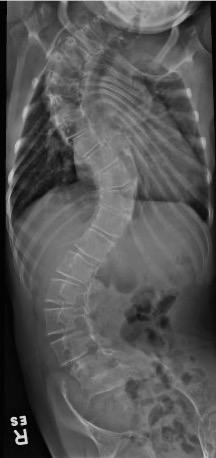

In [ ]:
def chat_with_xray(model, processor, image, current_history, user_question):
    # 1. Build the prompt history
    # The prompt structure needs to include: Previous History + New Question
    full_prompt = f"{current_history}\nUSER: {user_question}\nASSISTANT:"
    
    # 2. Process the inputs
    device = "cuda" if torch.cuda.is_available() else "cpu"
    inputs = processor(text=full_prompt, images=image, return_tensors="pt").to(device)
    
    # 3. Generate the response
    with torch.inference_mode():
        outputs = model.generate(**inputs, max_new_tokens=250, do_sample=False)
        
    # 4. Decode and clean
    full_output = processor.decode(outputs[0], skip_special_tokens=True)
    new_response = full_output.split("ASSISTANT:")[-1].strip()
    
    # Return both the new response and the updated history
    return new_response, full_prompt + " " + new_response

# --- How to use it ---
# 'report' is the answer you just got from your previous cell
chat_history = f"USER: <image>\nWhat is the pattern of the deformity seen in the thoracolumbar spine?.\nASSISTANT: {report}"
import torch
from PIL import Image

def start_terminal_chat(model, processor, image_path):
    # 1. Load the X-ray image
    try:
        image = Image.open(image_path).convert("RGB")
        print("✅ Image loaded successfully!")
    except FileNotFoundError:
        print(f"❌ Error: Image not found at {image_path}")
        return

    # 2. Initialize the conversation history
    initial_question = input("\nEnter your initial question about the X-ray: ")
    prompt = f"USER: <image>\n{initial_question}\nASSISTANT:"
    
    device = "cuda" if torch.cuda.is_available() else "cpu"
    
    # Generate the first response
    print("\n🤖 Processing...")
    inputs = processor(text=prompt, images=image, return_tensors="pt").to(device)
    with torch.inference_mode():
        outputs = model.generate(**inputs, max_new_tokens=250, do_sample=False)
        
    full_output = processor.decode(outputs[0], skip_special_tokens=True)
    assistant_response = full_output.split("ASSISTANT:")[-1].strip()
    
    print(f"\n💬 Assistant: {assistant_response}\n")
    
    # Maintain the running chat history
    chat_history = f"{prompt} {assistant_response}"
    
    # 3. Start the interactive chat loop
    while True:
        try:
            user_input = input("You (Type 'exit' to quit): ")
            if user_input.strip().lower() == 'exit':
                print("Ending chat session. Goodbye!")
                break
                
            if not user_input.strip():
                continue
                
            # Append new turn to history
            chat_history += f"\nUSER: {user_input}\nASSISTANT:"
            
            inputs = processor(text=chat_history, images=image, return_tensors="pt").to(device)
            
            with torch.inference_mode():
                outputs = model.generate(**inputs, max_new_tokens=250, do_sample=False)
                
            full_output = processor.decode(outputs[0], skip_special_tokens=True)
            new_assistant_response = full_output.split("ASSISTANT:")[-1].strip()
            
            print(f"\n💬 Assistant: {new_assistant_response}\n")
            
            # Update history with the latest response
            chat_history += f" {new_assistant_response}"
            
        except KeyboardInterrupt:
            print("\nExiting chat session.")
            break

# --- Run the chat ---
# Replace this with your path: /kaggle/input/datasets/habibaadawi/spine-img/thoracolumber_spine.jpg
image_path = "/kaggle/input/datasets/habibaadawi/spine-img/thoracolumber_spine.jpg"
start_terminal_chat(model, processor, image_path)
new_question = "Are there any signs of vertebral fracture associated with this deformity?"
response, chat_history = chat_with_xray(model, processor, image, chat_history, new_question)

print(f"💬 Assistant: {response}")

✅ Image loaded successfully!



Enter your initial question about the X-ray:  What are the associated anomalies?



🤖 Processing...

💬 Assistant: The image shows a baby with a spinal cord abnormality, which is visible as a c-shaped spine. This is an associated anomaly, as it is not a typical spinal cord shape for a healthy baby. The baby's spine is curved in a c-shape, which is not the usual straight alignment seen in most babies. This abnormality may require medical attention and monitoring to ensure the baby's health and development.



You (Type 'exit' to quit):  what are the proper treatments list some ?



💬 Assistant: Treatment options for a baby with a c-shaped spine may vary depending on the severity of the anomaly and the baby's overall health. Some possible treatments include:

1. Observation: In some cases, doctors may choose to monitor the baby's growth and development without any immediate intervention. This approach is often used when the c-shaped spine is not causing any significant issues or discomfort.

2. Bracing: If the c-shaped spine is causing discomfort or affecting the baby's mobility, doctors may recommend using a specialized brace to help maintain a more normal spinal alignment.

3. Surgery: In more severe cases or when the c-shaped spine is causing significant issues, surgery may be necessary. The goal of surgery is to correct the spinal alignment and restore a more normal shape.

4. Physical therapy: After the surgery or during the recovery period, the baby may require physical therapy to help maintain muscle strength, flexibility, and overall mobility.

5. Pain ma

You (Type 'exit' to quit):  exit


Ending chat session. Goodbye!
